# ARIMA and SARIMA Forecasting Models
## 1. Import Libraries and Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.1 Load the Training and Test Datasets

In [2]:
DATA_DIR = Path("../dataset/forecasting")
train = pd.read_csv(
    DATA_DIR / "train_daily.csv",
    index_col="Date",
    parse_dates=True
)

test = pd.read_csv(
    DATA_DIR / "test_daily.csv",
    index_col="Date",
    parse_dates=True
)

train = train.sort_index()
test = test.sort_index()

print("Datasets loaded successfully!")
print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

Datasets loaded successfully!
Training dataset shape: (900, 8)
Test dataset shape: (42, 8)


## 2. Data Inspection and Validation

In [3]:
print("TRAINING DATA")
print("=" * 50)

print("First date:", train.index.min())
print("Last date:", train.index.max())
print("Number of observations:", len(train))
print("Missing values:\n")
print(train.isnull().sum())

print("\nTEST DATA")
print("=" * 50)

print("First date:", test.index.min())
print("Last date:", test.index.max())
print("Number of observations:", len(test))
print("Missing values:\n")
print(test.isnull().sum())

TRAINING DATA
First date: 2013-01-01 00:00:00
Last date: 2015-06-19 00:00:00
Number of observations: 900
Missing values:

Sales              0
Customers          0
OpenStores         0
StoresReporting    0
Promo              0
SchoolHoliday      0
StateHoliday       0
DayOfWeek          0
dtype: int64

TEST DATA
First date: 2015-06-20 00:00:00
Last date: 2015-07-31 00:00:00
Number of observations: 42
Missing values:

Sales              0
Customers          0
OpenStores         0
StoresReporting    0
Promo              0
SchoolHoliday      0
StateHoliday       0
DayOfWeek          0
dtype: int64


## 3. Visualize the Training Sales

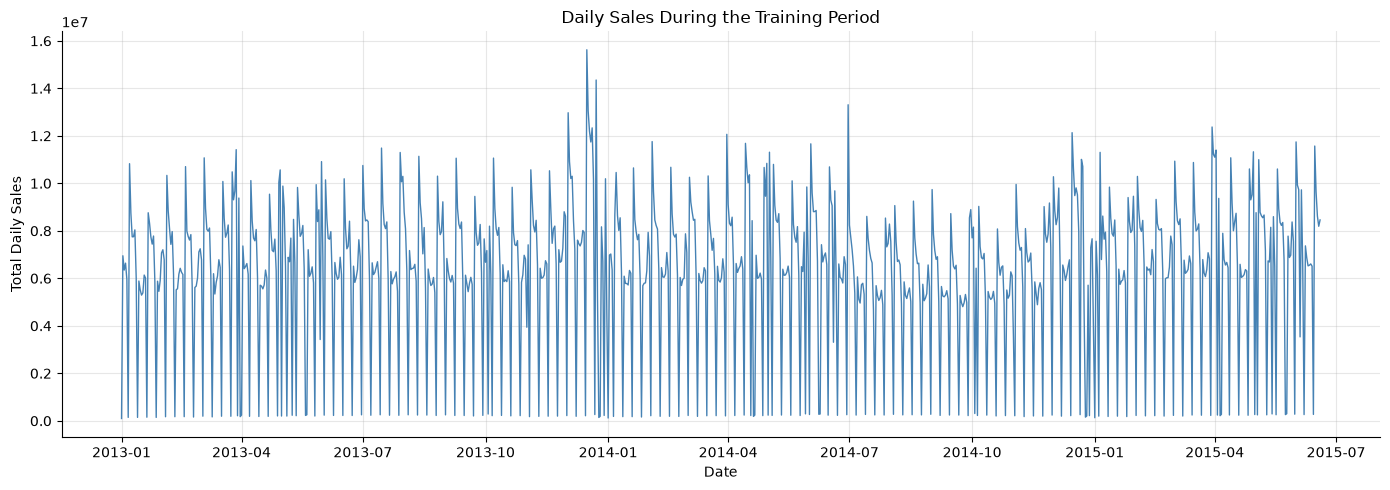

In [4]:
plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train["Sales"],
    color="steelblue",
    linewidth=1
)

plt.title("Daily Sales During the Training Period")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.tight_layout()
plt.show()

## 4. Analyze Weekly Sales Seasonality

Average sales by day of the week:


DayOfWeek
Monday       8400823.82
Tuesday      7530470.09
Wednesday    7049873.29
Thursday     6711020.74
Friday       7237717.47
Saturday     6317201.67
Sunday        218033.88
Name: Sales, dtype: float64

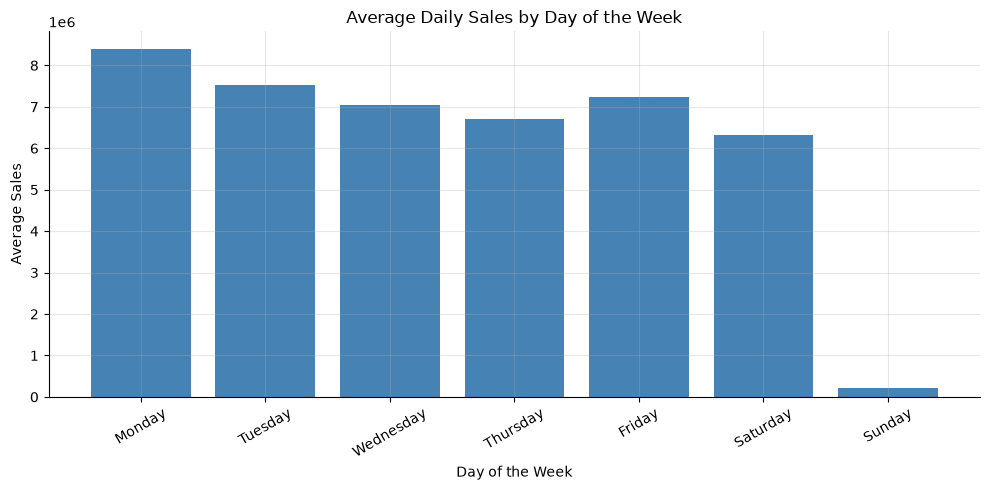

In [5]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

weekly_sales = train.groupby("DayOfWeek")["Sales"].mean()
weekly_sales.index = weekly_sales.index.map(day_names)

print("Average sales by day of the week:")
display(weekly_sales.round(2))

plt.figure(figsize=(10, 5))

plt.bar(
    weekly_sales.index,
    weekly_sales.values,
    color="steelblue"
)

plt.title("Average Daily Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. ARIMA Model
### 5.1 Import ARIMA and Prepare the Sales Series

In [8]:
%pip install statsmodels
import statsmodels
from statsmodels.tsa.arima.model import ARIMA
print("ARIMA imported successfully.")

Note: you may need to restart the kernel to use updated packages.
ARIMA imported successfully.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 5.3 Fit the ARIMA Model

In [9]:
# Prepare the training and test sales series

y_train = train["Sales"].astype(float)
y_test = test["Sales"].astype(float)

# Fit the ARIMA(1, 1, 1) model
arima_model = ARIMA(
    y_train,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

# Display the model summary
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                  900
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -14740.837
Date:                Fri, 23 Oct 2026   AIC                          29487.674
Time:                        18:47:29   BIC                          29502.078
Sample:                    01-01-2013   HQIC                         29493.177
                         - 06-19-2015                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0259      0.039     -0.661      0.508      -0.103       0.051
ma.L1         -0.9943      0.006   -162.461      0.000      -1.006      -0.982
sigma2      1.275e+13        nan        nan        n

c:\Users\nadab\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\nadab\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\nadab\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


### 5.4 Generate ARIMA Forecasts

In [10]:
# Forecast sales for the next 42 days

arima_forecast = arima_fit.forecast(steps=len(y_test))

# Match forecasts to the test dates
arima_forecast = pd.Series(
    np.asarray(arima_forecast),
    index=y_test.index,
    name="ARIMA_Forecast"
)

# Display the first forecast values
print("First 10 ARIMA forecasts:")
display(arima_forecast.head(10).round(2))

print("\nForecast length:", len(arima_forecast))
print("Test length:", len(y_test))

First 10 ARIMA forecasts:


Date
2015-06-20    6272108.30
2015-06-21    6328692.17
2015-06-22    6327227.61
2015-06-23    6327265.52
2015-06-24    6327264.54
2015-06-25    6327264.56
2015-06-26    6327264.56
2015-06-27    6327264.56
2015-06-28    6327264.56
2015-06-29    6327264.56
Name: ARIMA_Forecast, dtype: float64


Forecast length: 42
Test length: 42


### 5.5 Evaluate ARIMA Forecast Accuracy

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate evaluation metrics
arima_rmse = np.sqrt(mean_squared_error(y_test, arima_forecast))
arima_mae = mean_absolute_error(y_test, arima_forecast)

# Avoid division by zero when calculating MAPE
arima_mape = (
    np.abs((y_test - arima_forecast) / y_test.replace(0, np.nan))
    .mean() * 100
)

# Calculate MAPE for days with at least 800 stores open
normal_days = test["OpenStores"] >= 800

arima_mape_normal = (
    np.abs(
        (y_test[normal_days] - arima_forecast[normal_days])
        / y_test[normal_days].replace(0, np.nan)
    ).mean() * 100
)

arima_metrics = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MAPE (%)", "MAPE on normal days (%)"],
    "ARIMA": [
        arima_rmse,
        arima_mae,
        arima_mape,
        arima_mape_normal
    ]
})

display(arima_metrics.round(2))

,Metric,ARIMA
0,RMSE,3058326.28
1,MAE,2148282.64
2,MAPE (%),330.76
3,MAPE on normal days (%),16.19


### 5.6 Compare Actual Sales with ARIMA Forecasts

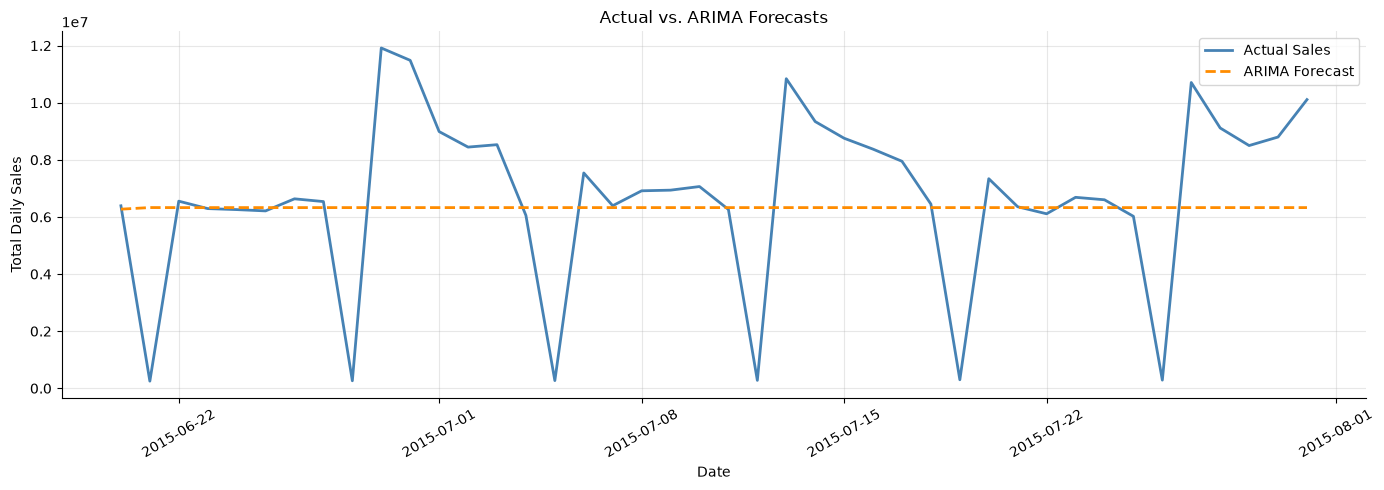

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Sales",
    color="steelblue",
    linewidth=2
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    color="darkorange",
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs. ARIMA Forecasts")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. SARIMA Model

### 6.1 Import SARIMA and Define the Model

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("SARIMA imported successfully.")

SARIMA imported successfully.


### 6.2 Fit the SARIMA Model

In [14]:
sarima_model = SARIMAX(
    y_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

c:\Users\nadab\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\nadab\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  900
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -14143.723
Date:                           Fri, 23 Oct 2026   AIC                          28297.446
Time:                                   18:56:24   BIC                          28321.363
Sample:                               01-01-2013   HQIC                         28306.591
                                    - 06-19-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1633      0.052      3.154      0.002       0.062       0.265
ma.L1         -0.9476      0.021    -44.924

### 6.3 Generate SARIMA Forecasts

In [15]:
# Forecast the next 42 days
sarima_forecast = sarima_fit.forecast(steps=len(y_test))

# Match forecasts to the test dates
sarima_forecast = pd.Series(
    np.asarray(sarima_forecast),
    index=y_test.index,
    name="SARIMA_Forecast"
)

print("First 10 SARIMA forecasts:")
display(sarima_forecast.head(10).round(2))

print("\nForecast length:", len(sarima_forecast))
print("Test length:", len(y_test))

First 10 SARIMA forecasts:


Date
2015-06-20    7370901.28
2015-06-21     523683.43
2015-06-22    7754913.63
2015-06-23    8198394.15
2015-06-24    8039929.17
2015-06-25    6409799.17
2015-06-26    7598053.47
2015-06-27    7092278.31
2015-06-28     483489.39
2015-06-29    9034593.41
Name: SARIMA_Forecast, dtype: float64


Forecast length: 42
Test length: 42


### 6.4 Evaluate SARIMA Forecast Accuracy

In [16]:
# Calculate evaluation metrics
sarima_rmse = np.sqrt(mean_squared_error(y_test, sarima_forecast))
sarima_mae = mean_absolute_error(y_test, sarima_forecast)

# Calculate MAPE, avoiding division by zero
sarima_mape = (
    np.abs((y_test - sarima_forecast) / y_test.replace(0, np.nan))
    .mean() * 100
)

# Calculate MAPE for days with at least 800 stores open
normal_days = test["OpenStores"] >= 800

sarima_mape_normal = (
    np.abs(
        (y_test[normal_days] - sarima_forecast[normal_days])
        / y_test[normal_days].replace(0, np.nan)
    ).mean() * 100
)

# Store the results in a DataFrame
sarima_metrics = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MAPE (%)", "MAPE on normal days (%)"],
    "SARIMA": [
        sarima_rmse,
        sarima_mae,
        sarima_mape,
        sarima_mape_normal
    ]
})

display(sarima_metrics.round(2))

,Metric,SARIMA
0,RMSE,1339830.16
1,MAE,1094546.73
2,MAPE (%),29.03
3,MAPE on normal days (%),16.08


## 7. Compare ARIMA and SARIMA Models
### 7.1 Compare Forecast Accuracy

In [17]:
comparison = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "MAPE (%)",
        "MAPE on normal days (%)"
    ],
    "ARIMA": [
        arima_rmse,
        arima_mae,
        arima_mape,
        arima_mape_normal
    ],
    "SARIMA": [
        sarima_rmse,
        sarima_mae,
        sarima_mape,
        sarima_mape_normal
    ]
})

display(comparison.round(2))

,Metric,ARIMA,SARIMA
0,RMSE,3058326.28,1339830.16
1,MAE,2148282.64,1094546.73
2,MAPE (%),330.76,29.03
3,MAPE on normal days (%),16.19,16.08


### 7.2 Compare with the Existing Baseline Model

In [18]:
# Load the baseline model's saved evaluation metrics
baseline_path = DATA_DIR / "baseline_metrics_holdout.csv"

baseline_metrics = pd.read_csv(baseline_path)

print("Baseline metrics:")
display(baseline_metrics)

Baseline metrics:


,model,RMSE,MAE,MAPE_%,MAPE_normal_%
0,Naive (last value),3512021.99,2507472.14,446.83,21.49
1,Seasonal naive (7d),1775080.15,1179019.24,17.41,19.52
2,Seasonal naive (14d),527462.31,354693.05,5.09,5.09
3,Seasonal naive (364d),1338134.67,1081606.19,14.73,15.67


### 7.3 Final Comparison of all Forecasting Models

In [19]:
# Prepare the baseline results
baseline_comparison = baseline_metrics.rename(columns={
    "model": "Model",
    "MAPE_%": "MAPE (%)",
    "MAPE_normal_%": "MAPE on normal days (%)"
})

baseline_comparison = baseline_comparison[
    ["Model", "RMSE", "MAE", "MAPE (%)", "MAPE on normal days (%)"]
]

# Prepare the ARIMA and SARIMA results
statistical_comparison = pd.DataFrame([
    {
        "Model": "ARIMA (1,1,1)",
        "RMSE": arima_rmse,
        "MAE": arima_mae,
        "MAPE (%)": arima_mape,
        "MAPE on normal days (%)": arima_mape_normal
    },
    {
        "Model": "SARIMA (1,1,1)(1,1,1,7)",
        "RMSE": sarima_rmse,
        "MAE": sarima_mae,
        "MAPE (%)": sarima_mape,
        "MAPE on normal days (%)": sarima_mape_normal
    }
])

# Combine all models
final_comparison = pd.concat(
    [baseline_comparison, statistical_comparison],
    ignore_index=True
)

# Sort by RMSE, from lowest to highest
final_comparison = final_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(final_comparison.round(2))

,Model,RMSE,MAE,MAPE (%),MAPE on normal days (%)
0,Seasonal naive (14d),527462.31,354693.05,5.09,5.09
1,Seasonal naive (364d),1338134.67,1081606.19,14.73,15.67
2,"SARIMA (1,1,1)(1,1,1,7)",1339830.16,1094546.73,29.03,16.08
3,Seasonal naive (7d),1775080.15,1179019.24,17.41,19.52
4,"ARIMA (1,1,1)",3058326.28,2148282.64,330.76,16.19
5,Naive (last value),3512021.99,2507472.14,446.83,21.49


### 7.4 Visual Comparison of Actual sales, ARIMA and SARIMA

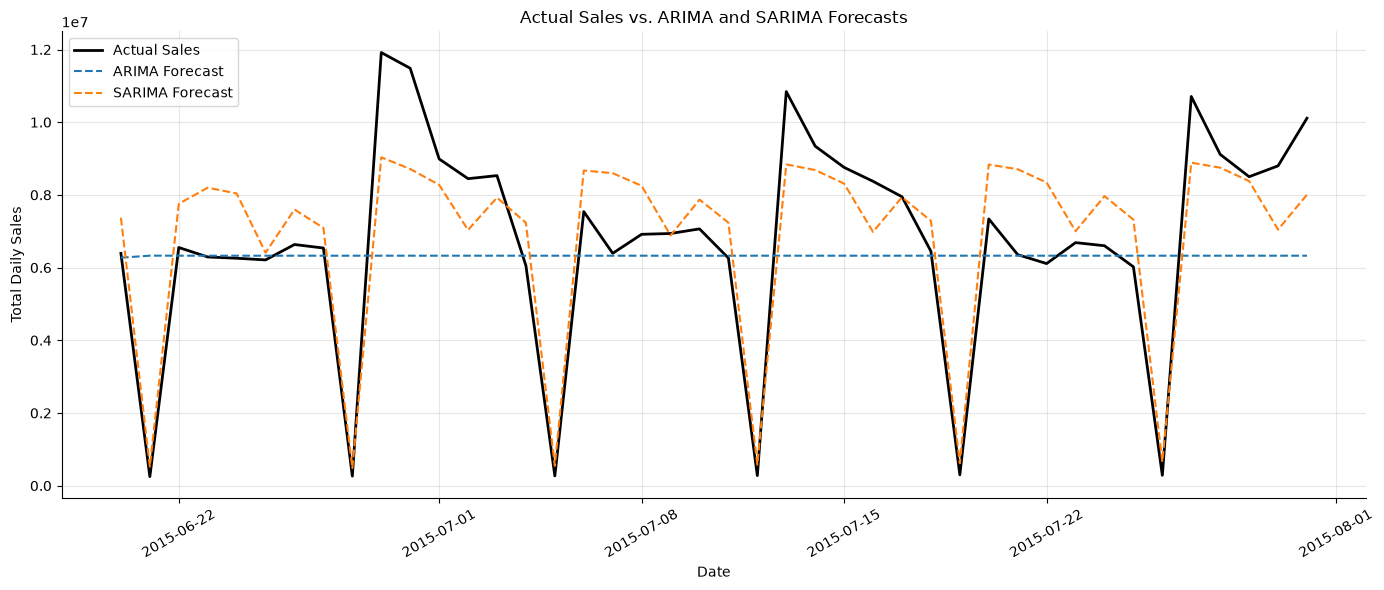

In [22]:
# Plot actual sales against ARIMA and SARIMA forecasts

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Sales",
    color="black",
    linewidth=2
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    linestyle="--"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast",
    linestyle="--"
)

plt.title("Actual Sales vs. ARIMA and SARIMA Forecasts")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 8. Conclusion and Key Findings

### 8.1 Summary of Results

In this notebook, ARIMA and SARIMA time-series forecasting models were developed to predict daily sales for the Rossmann Store Sales dataset.

The models were evaluated on the same 42-day test period using RMSE, MAE, MAPE, and MAPE on normal operating days.

The main findings are:

- **ARIMA:** Produced relatively high forecasting errors and did not explicitly model weekly seasonality.
- **SARIMA:** Improved forecasting performance by incorporating a weekly seasonal period of 7 days.
- **Seasonal Naive (14d):** Achieved the best performance among all evaluated models, with an RMSE of 527,462.31 and an MAE of 354,693.05.
- **Model comparison:** The results show that a simple seasonal baseline can outperform more complex statistical forecasting models.

### 8.2 Final Conclusion

SARIMA performed substantially better than ARIMA, demonstrating the importance of weekly seasonality in daily sales forecasting. However, the Seasonal Naive (14d) model achieved the lowest errors overall.

Therefore, Seasonal Naive (14d) is the best-performing model among the models evaluated so far. Further experimentation with seasonal parameters and other forecasting approaches may improve the results.